# 01 — Exploratory Data Analysis (EDA)
## HDFS Log Dataset

**เป้าหมาย:** สำรวจข้อมูล HDFS log เพื่อเข้าใจ format, ขนาด, และลักษณะของ session ปกติ vs ผิดปกติ ก่อนที่จะเริ่ม train โมเดล

**Analogy:** เหมือนตอนรับ incident มาใหม่ — ก่อน investigate ต้องดูภาพรวมก่อนว่า log มาจากไหน, format เป็นยังไง, มีอะไรน่าสนใจบ้าง

## Step 1: Import Libraries & Load Data

### ทำไมต้องใช้ library เหล่านี้?
- **pandas** → เหมือน Excel ใน Python ใช้จัดการข้อมูลเป็นตาราง (DataFrame)
- **matplotlib / seaborn** → เครื่องมือวาดกราฟ (seaborn สวยกว่า matplotlib เฉยๆ)
- **re** → Regular Expression สำหรับดึง pattern จาก log (ทีม CySec น่าจะคุ้นเคย)
- **collections.Counter** → นับจำนวนของสิ่งต่างๆ อย่างรวดเร็ว

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
from collections import Counter

# ตั้งค่ากราฟให้สวยงาม
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

print('Libraries loaded successfully! ✅')

Libraries loaded successfully! ✅


## Step 2: ดู Raw Log — หน้าตาเป็นยังไง?

### หลักการ:
ก่อนจะทำอะไรกับข้อมูล **ต้องดูของจริงก่อนเสมอ** เหมือนตอนเปิด log ดูด้วยตาก่อน investigate

เราจะอ่านไฟล์ log แบบ text ธรรมดา ดู 10 บรรทัดแรก แล้ววิเคราะห์ว่าแต่ละบรรทัดมีอะไรบ้าง

In [2]:
# อ่าน 10 บรรทัดแรกของ HDFS.log
# ใช้ open() เพราะมันเป็นไฟล์ text ธรรมดา ไม่ใช่ CSV

log_path = '../data/raw/HDFS/HDFS.log'

with open(log_path, 'r') as f:
    for i, line in enumerate(f):
        if i >= 10:
            break
        print(f'Line {i}: {line.strip()}')
        print('---')

Line 0: 081109 203518 143 INFO dfs.DataNode$DataXceiver: Receiving block blk_-1608999687919862906 src: /10.250.19.102:54106 dest: /10.250.19.102:50010
---
Line 1: 081109 203518 35 INFO dfs.FSNamesystem: BLOCK* NameSystem.allocateBlock: /mnt/hadoop/mapred/system/job_200811092030_0001/job.jar. blk_-1608999687919862906
---
Line 2: 081109 203519 143 INFO dfs.DataNode$DataXceiver: Receiving block blk_-1608999687919862906 src: /10.250.10.6:40524 dest: /10.250.10.6:50010
---
Line 3: 081109 203519 145 INFO dfs.DataNode$DataXceiver: Receiving block blk_-1608999687919862906 src: /10.250.14.224:42420 dest: /10.250.14.224:50010
---
Line 4: 081109 203519 145 INFO dfs.DataNode$PacketResponder: PacketResponder 1 for block blk_-1608999687919862906 terminating
---
Line 5: 081109 203519 145 INFO dfs.DataNode$PacketResponder: PacketResponder 2 for block blk_-1608999687919862906 terminating
---
Line 6: 081109 203519 145 INFO dfs.DataNode$PacketResponder: Received block blk_-1608999687919862906 of size 911

### 🔍 วิเคราะห์ format ของ HDFS log

จากที่เห็น แต่ละบรรทัดมี format:
```
<Date> <Time> <Pid> <Level> <Component>: <Content>
```

ตัวอย่าง:
```
081109 203615 148 INFO dfs.DataNode$PacketResponder: PacketResponder 1 for block blk_389... terminating
```

| Field | ตัวอย่าง | ความหมาย |
|-------|---------|----------|
| Date | `081109` | วันที่ (YYMMDD) → 2008-11-09 |
| Time | `203615` | เวลา (HHMMSS) → 20:36:15 |
| Pid | `148` | Process ID |
| Level | `INFO` | Log severity (INFO, WARN, ERROR) |
| Component | `dfs.DataNode$PacketResponder` | ส่วนของระบบที่สร้าง log |
| Content | `PacketResponder 1 for block blk_389...` | ข้อความ log จริงๆ |

**สิ่งสำคัญ:** สังเกตว่ามี `blk_xxxxx` อยู่ในข้อความ — นี่คือ **block_id** ที่เราจะใช้จัดกลุ่มเป็น session!

## Step 3: Parse แต่ละบรรทัด + ดึง block_id

### หลักการ:
ตอนนี้ log ยังเป็น text ธรรมดา เราต้อง **แยกส่วน (parse)** ให้คอมพิวเตอร์เข้าใจว่าอะไรคือ Date, อะไรคือ Level, อะไรคือ Content

**Analogy:** เหมือนตอนเราเขียน SIEM rule ต้อง parse log ก่อนถึงจะ filter ได้

เราจะใช้ **Regular Expression (regex)** ซึ่งทีม CySec น่าจะเคยใช้กับ Snort/YARA rules มาบ้าง

In [3]:
# regex สำหรับ parse HDFS log แต่ละบรรทัด
# แต่ละ () คือ 1 กลุ่มที่เราจะดึงออกมา
#
# (?P<date>\d{6})    → จับตัวเลข 6 หลัก = วันที่ เช่น 081109
# (?P<time>\d{6})    → จับตัวเลข 6 หลัก = เวลา เช่น 203615
# (?P<pid>\d+)       → จับตัวเลข = Process ID
# (?P<level>\w+)     → จับคำ = INFO, WARN, ERROR
# (?P<component>\S+) → จับ text ที่ไม่มีช่องว่าง = component name
# (?P<content>.+)    → จับที่เหลือทั้งหมด = เนื้อหา log

hdfs_pattern = re.compile(
    r'(?P<date>\d{6})\s+'
    r'(?P<time>\d{6})\s+'
    r'(?P<pid>\d+)\s+'
    r'(?P<level>\w+)\s+'
    r'(?P<component>\S+):\s+'
    r'(?P<content>.+)'
)

# regex สำหรับดึง block_id จาก content
# blk_ ตามด้วยตัวเลข (อาจมี - นำหน้า)
block_pattern = re.compile(r'(blk_-?\d+)')

# ทดสอบกับ 5 บรรทัดแรก
with open(log_path, 'r') as f:
    for i, line in enumerate(f):
        if i >= 5:
            break
        match = hdfs_pattern.match(line.strip())
        if match:
            parsed = match.groupdict()
            block_ids = block_pattern.findall(parsed['content'])
            print(f"Level: {parsed['level']}, Component: {parsed['component']}")
            print(f"Content: {parsed['content'][:80]}...")
            print(f"Block IDs found: {block_ids}")
            print('---')

Level: INFO, Component: dfs.DataNode$DataXceiver
Content: Receiving block blk_-1608999687919862906 src: /10.250.19.102:54106 dest: /10.250...
Block IDs found: ['blk_-1608999687919862906']
---
Level: INFO, Component: dfs.FSNamesystem
Content: BLOCK* NameSystem.allocateBlock: /mnt/hadoop/mapred/system/job_200811092030_0001...
Block IDs found: ['blk_-1608999687919862906']
---
Level: INFO, Component: dfs.DataNode$DataXceiver
Content: Receiving block blk_-1608999687919862906 src: /10.250.10.6:40524 dest: /10.250.1...
Block IDs found: ['blk_-1608999687919862906']
---
Level: INFO, Component: dfs.DataNode$DataXceiver
Content: Receiving block blk_-1608999687919862906 src: /10.250.14.224:42420 dest: /10.250...
Block IDs found: ['blk_-1608999687919862906']
---
Level: INFO, Component: dfs.DataNode$PacketResponder
Content: PacketResponder 1 for block blk_-1608999687919862906 terminating...
Block IDs found: ['blk_-1608999687919862906']
---


## Step 4: สถิติเบื้องต้นของ Log

### หลักการ:
ตอนนี้เรารู้ format แล้ว ขั้นต่อไปคือ **นับสิ่งต่างๆ** เพื่อเข้าใจภาพรวม:
- มีกี่บรรทัดทั้งหมด?
- Level ไหนเยอะสุด? (INFO vs WARN vs ERROR)
- Component ไหนสร้าง log มากสุด?
- มีกี่ block_id (session) ที่ไม่ซ้ำ?

**Analogy:** เหมือนดู SIEM dashboard ภาพรวม — ก่อนจะ drill down ต้องเห็น summary ก่อน

⚠️ **หมายเหตุ:** ไฟล์มี 11 ล้านบรรทัด อาจใช้เวลาสักครู่ (1-2 นาที)

In [4]:
# สำรวจ log ทั้งไฟล์ — นับ level, component, block_id
# ใช้ Counter เพราะเร็วกว่าการนับด้วย dict เอง

level_counter = Counter()       # นับจำนวน INFO, WARN, ERROR
component_counter = Counter()   # นับจำนวนแต่ละ component
block_ids_set = set()           # เก็บ block_id ที่ไม่ซ้ำ (ใช้ set เพราะไม่อยาก duplicate)
total_lines = 0
unparsed_lines = 0              # บรรทัดที่ regex จับ pattern ไม่ได้

with open(log_path, 'r') as f:
    for line in f:
        total_lines += 1
        match = hdfs_pattern.match(line.strip())
        if match:
            parsed = match.groupdict()
            level_counter[parsed['level']] += 1
            component_counter[parsed['component']] += 1
            
            # ดึง block_id
            blocks = block_pattern.findall(parsed['content'])
            block_ids_set.update(blocks)
        else:
            unparsed_lines += 1
        
        # แสดง progress ทุก 2 ล้านบรรทัด
        if total_lines % 2_000_000 == 0:
            print(f'Processed {total_lines:,} lines...')

print(f'\n=== Summary ===')
print(f'Total lines: {total_lines:,}')
print(f'Unparsed lines: {unparsed_lines:,}')
print(f'Unique block_ids (sessions): {len(block_ids_set):,}')

Processed 2,000,000 lines...
Processed 4,000,000 lines...
Processed 6,000,000 lines...
Processed 8,000,000 lines...
Processed 10,000,000 lines...

=== Summary ===
Total lines: 11,175,629
Unparsed lines: 0
Unique block_ids (sessions): 575,061


## Step 5: วิเคราะห์ Log Level Distribution

### หลักการ:
**Log Level** บอกความรุนแรงของเหตุการณ์:
- `INFO` → เหตุการณ์ปกติ (เช่น "เริ่มเขียนข้อมูลสำเร็จ")
- `WARN` → เตือนว่าอาจมีปัญหา
- `ERROR` → เกิดข้อผิดพลาดจริง

ถ้า ERROR เยอะ → อาจมี session ผิดปกติมาก
ถ้า INFO เกือบทั้งหมด → ปัญหาอยู่ที่ "ลำดับ" ของ event มากกว่า level

=== Log Level Distribution ===
INFO    :   10,812,836 (96.75%)
WARN    :      362,793 (3.25%)


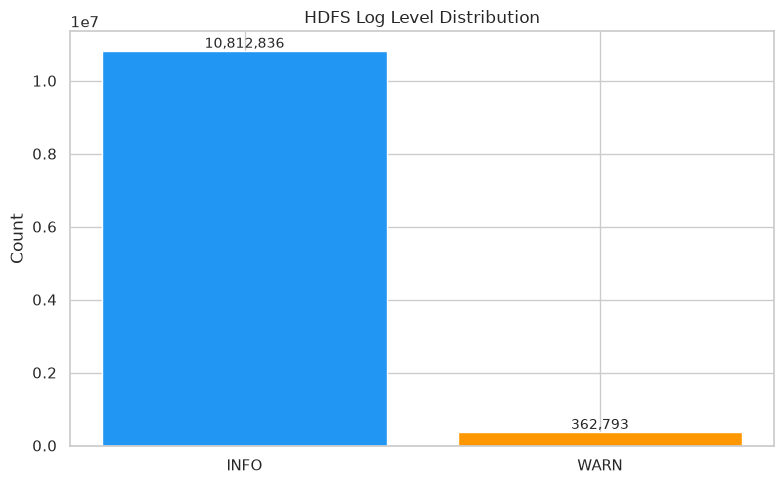

Saved to results/figures/01_log_level_distribution.png


In [5]:
# แสดง Log Level Distribution
print('=== Log Level Distribution ===')
for level, count in level_counter.most_common():
    pct = count / total_lines * 100
    print(f'{level:8s}: {count:>12,} ({pct:.2f}%)')

# วาดกราฟแท่ง
fig, ax = plt.subplots(figsize=(8, 5))
levels = list(level_counter.keys())
counts = list(level_counter.values())
colors = {'INFO': '#2196F3', 'WARN': '#FF9800', 'ERROR': '#F44336'}
bar_colors = [colors.get(l, '#9E9E9E') for l in levels]

ax.bar(levels, counts, color=bar_colors)
ax.set_title('HDFS Log Level Distribution')
ax.set_ylabel('Count')

# ใส่ตัวเลขบนแท่ง
for i, (level, count) in enumerate(zip(levels, counts)):
    ax.text(i, count, f'{count:,}', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.savefig('../results/figures/01_log_level_distribution.png', dpi=150)
plt.show()
print('Saved to results/figures/01_log_level_distribution.png')

## Step 6: โหลด Anomaly Labels

### หลักการ:
ตอนนี้เรารู้จัก log แล้ว ขั้นต่อไปต้องดู **คำตอบเฉลย (labels)** ว่า session ไหน Normal / Anomaly

ไฟล์ `anomaly_label.csv` มี 2 คอลัมน์:
- `BlockId` — รหัส block (session)
- `Label` — Normal หรือ Anomaly

ตรงนี้ใช้ **pandas** อ่าน CSV เพราะมันเป็นตาราง → เหมาะกับ DataFrame

In [6]:
# โหลด anomaly labels ด้วย pandas
labels_path = '../data/raw/HDFS/preprocessed/anomaly_label.csv'
labels_df = pd.read_csv(labels_path)

print('=== Anomaly Labels ===')
print(f'Shape: {labels_df.shape}')          # (rows, columns)
print(f'Columns: {list(labels_df.columns)}') # ชื่อคอลัมน์
print()
print(labels_df.head(10))                     # ดู 10 แถวแรก

=== Anomaly Labels ===
Shape: (575061, 2)
Columns: ['BlockId', 'Label']

                    BlockId    Label
0  blk_-1608999687919862906   Normal
1   blk_7503483334202473044   Normal
2  blk_-3544583377289625738  Anomaly
3  blk_-9073992586687739851   Normal
4   blk_7854771516489510256   Normal
5   blk_1717858812220360316   Normal
6  blk_-2519617320378473615   Normal
7   blk_7063315473424667801   Normal
8   blk_8586544123689943463   Normal
9   blk_2765344736980045501   Normal


=== Label Distribution ===
Normal    :  558,223 (97.07%)
Anomaly   :   16,838 (2.93%)


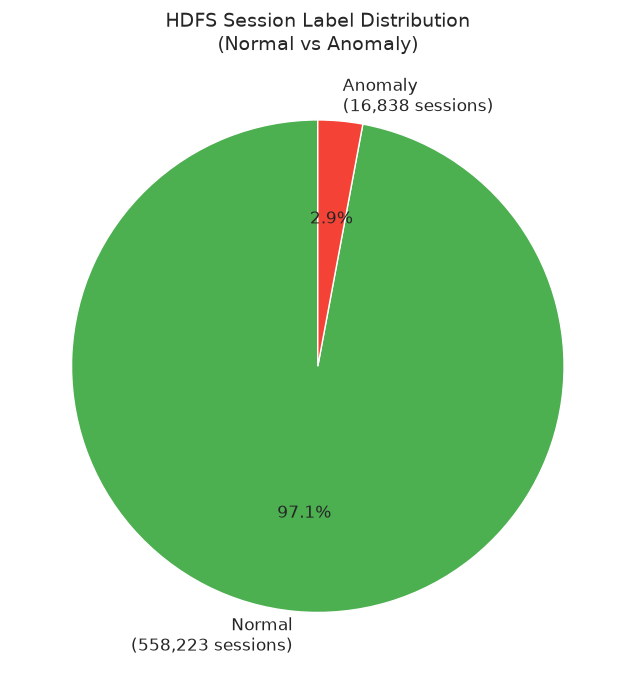

Saved to results/figures/02_label_distribution.png


In [7]:
# นับสัดส่วน Normal vs Anomaly
label_counts = labels_df['Label'].value_counts()
print('=== Label Distribution ===')
for label, count in label_counts.items():
    pct = count / len(labels_df) * 100
    print(f'{label:10s}: {count:>8,} ({pct:.2f}%)')

# วาด Pie Chart
fig, ax = plt.subplots(figsize=(7, 7))
colors_pie = ['#4CAF50', '#F44336']  # เขียว=Normal, แดง=Anomaly
ax.pie(
    label_counts.values,
    labels=[f"{l}\n({c:,} sessions)" for l, c in label_counts.items()],
    colors=colors_pie,
    autopct='%1.1f%%',
    startangle=90,
    textprops={'fontsize': 12}
)
ax.set_title('HDFS Session Label Distribution\n(Normal vs Anomaly)', fontsize=14)

plt.tight_layout()
plt.savefig('../results/figures/02_label_distribution.png', dpi=150)
plt.show()
print('Saved to results/figures/02_label_distribution.png')

### 💡 สิ่งที่ควรสังเกต: Imbalanced Data

Anomaly มีแค่ ~2.9% → ข้อมูล **ไม่สมดุล (imbalanced)** มาก

**ทำไมสำคัญ?**
- ถ้าโมเดลทายว่า "Normal" ทุก session → ก็ได้ Accuracy ~97% แต่ **ไม่ได้จับ Anomaly ได้เลย!**
- เหมือน IDS ที่ไม่เคยแจ้งเตือน → Accuracy สูง แต่ไร้ประโยชน์
- นี่คือเหตุผลที่เราใช้ **F1-Score** แทน Accuracy (ดูทั้ง Precision + Recall)

## Step 7: วิเคราะห์ขนาด Session

### หลักการ:
แต่ละ session (block_id) มีจำนวน log ไม่เท่ากัน เราต้องรู้ว่า:
- session สั้นสุดมีกี่บรรทัด?
- session ยาวสุดมีกี่บรรทัด?
- ค่าเฉลี่ย (mean) และค่ากลาง (median) เท่าไหร่?

**ทำไมสำคัญ?** → ตอน train โมเดล เราต้องตัดสินใจว่าจะตั้ง **max sequence length** เท่าไหร่
- สั้นไป → ตัดข้อมูลสำคัญทิ้ง
- ยาวไป → ใช้ memory เยอะ, train ช้า

In [8]:
# นับจำนวน log ต่อ block_id (session)
# อ่านไฟล์อีกรอบ แต่คราวนี้นับจำนวนบรรทัดต่อ block_id

session_lengths = Counter()  # block_id → จำนวนบรรทัด

with open(log_path, 'r') as f:
    for line in f:
        blocks = block_pattern.findall(line)
        for blk in blocks:
            session_lengths[blk] += 1

lengths = list(session_lengths.values())

print('=== Session Length Statistics ===')
print(f'Total sessions: {len(lengths):,}')
print(f'Min length:     {min(lengths)}')
print(f'Max length:     {max(lengths)}')
print(f'Mean length:    {sum(lengths)/len(lengths):.1f}')

# ใช้ pandas Series เพื่อคำนวณ percentile ได้ง่าย
lengths_series = pd.Series(lengths)
print(f'Median length:  {lengths_series.median():.0f}')
print(f'95th percentile: {lengths_series.quantile(0.95):.0f}')
print(f'99th percentile: {lengths_series.quantile(0.99):.0f}')

=== Session Length Statistics ===
Total sessions: 575,061
Min length:     2
Max length:     310
Mean length:    21.9
Median length:  22
95th percentile: 31
99th percentile: 36


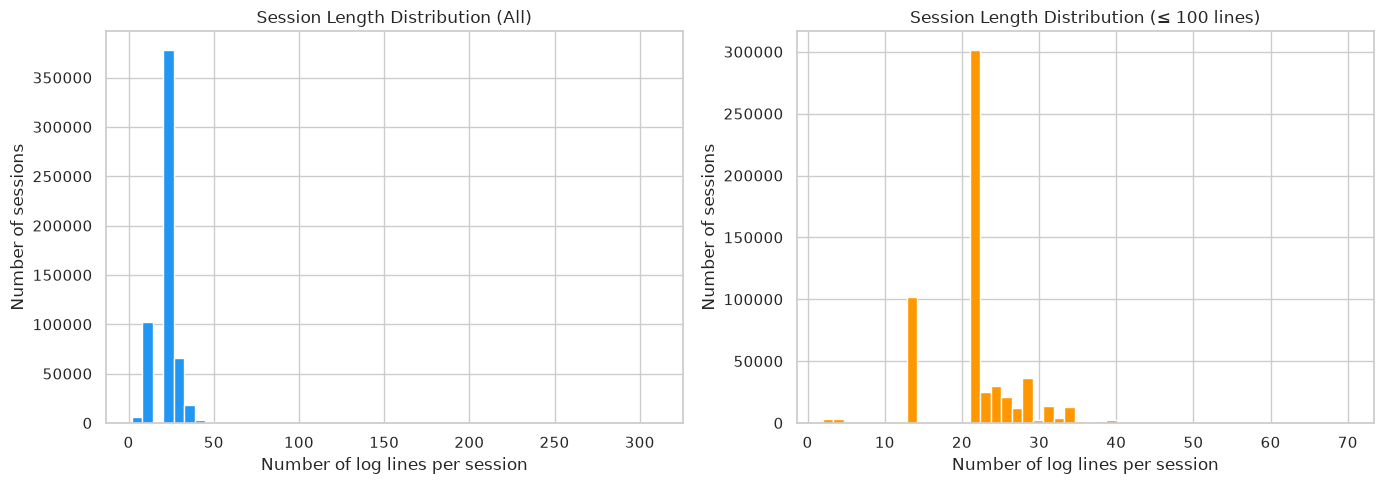

Saved to results/figures/03_session_length_distribution.png


In [9]:
# วาด Histogram ของ session length
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# กราฟซ้าย: ทุก session
axes[0].hist(lengths, bins=50, color='#2196F3', edgecolor='white')
axes[0].set_title('Session Length Distribution (All)')
axes[0].set_xlabel('Number of log lines per session')
axes[0].set_ylabel('Number of sessions')

# กราฟขวา: zoom เฉพาะ session ที่ <= 100 บรรทัด (เพื่อเห็นรายละเอียด)
short_lengths = [l for l in lengths if l <= 100]
axes[1].hist(short_lengths, bins=50, color='#FF9800', edgecolor='white')
axes[1].set_title('Session Length Distribution (≤ 100 lines)')
axes[1].set_xlabel('Number of log lines per session')
axes[1].set_ylabel('Number of sessions')

plt.tight_layout()
plt.savefig('../results/figures/03_session_length_distribution.png', dpi=150)
plt.show()
print('Saved to results/figures/03_session_length_distribution.png')

## Step 8: เปรียบเทียบ Session ปกติ vs ผิดปกติ

### หลักการ:
ขั้นตอนสำคัญที่สุด — ดู**ตัวอย่างจริง**ว่า session Normal กับ Anomaly ต่างกันยังไง

**Analogy:** เหมือน SOC analyst ดู log ของ true positive alert เทียบกับ benign traffic

In [11]:
# สร้าง dict เพื่อ lookup label ของแต่ละ block_id
label_dict = dict(zip(labels_df['BlockId'], labels_df['Label']))

# เปรียบเทียบ session length ระหว่าง Normal vs Anomaly
normal_lengths = []
anomaly_lengths = []

for blk, length in session_lengths.items():
    label = label_dict.get(blk, 'Unknown')
    if label == 'Normal':
        normal_lengths.append(length)
    elif label == 'Anomaly':
        anomaly_lengths.append(length)

print(f'Normal sessions:  {len(normal_lengths):,} (avg length: {sum(normal_lengths)/len(normal_lengths):.1f})')
print(f'Anomaly sessions: {len(anomaly_lengths):,} (avg length: {sum(anomaly_lengths)/len(anomaly_lengths):.1f})')

Normal sessions:  558,223 (avg length: 22.0)
Anomaly sessions: 16,838 (avg length: 19.2)


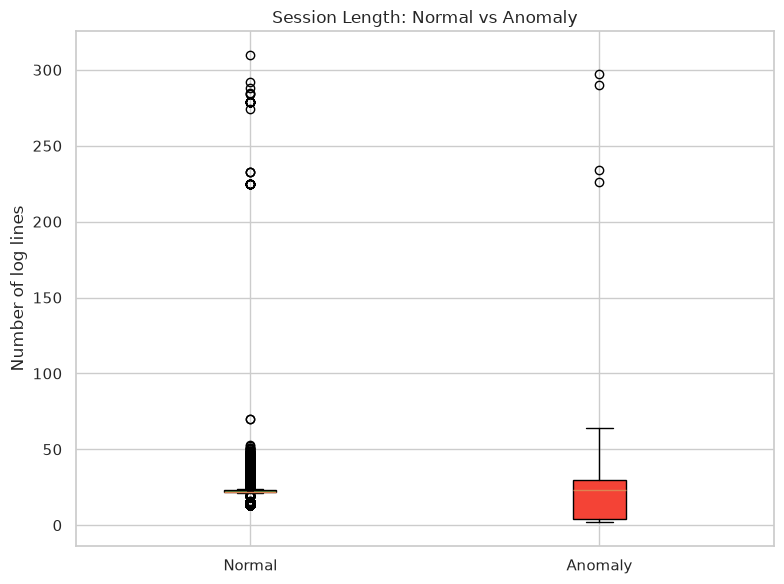

Saved to results/figures/04_session_length_normal_vs_anomaly.png


In [15]:
# วาด Box Plot เปรียบเทียบ session length ระหว่าง Normal vs Anomaly
fig, ax = plt.subplots(figsize=(8, 6))

data_to_plot = [normal_lengths, anomaly_lengths]
bp = ax.boxplot(data_to_plot, tick_labels=['Normal', 'Anomaly'], patch_artist=True)
bp['boxes'][0].set_facecolor('#4CAF50')
bp['boxes'][1].set_facecolor('#F44336')

ax.set_title('Session Length: Normal vs Anomaly')
ax.set_ylabel('Number of log lines')

plt.tight_layout()
plt.savefig('../results/figures/04_session_length_normal_vs_anomaly.png', dpi=150)
plt.show()
print('Saved to results/figures/04_session_length_normal_vs_anomaly.png')

## Step 9: ดูตัวอย่าง Log ของ Session จริง

### หลักการ:
ดูด้วยตาว่า log ของ session ปกติ vs ผิดปกติ ต่างกันยังไง
- อาจเห็นว่า Anomaly มี ERROR เยอะกว่า
- หรือลำดับ event ต่างออกไป (เช่น มีขั้นตอนหายไป)

นี่คือ insight ที่จะช่วยให้เราเข้าใจว่าโมเดลต้อง **เรียนรู้อะไร**

In [16]:
# หา 1 ตัวอย่าง Normal session และ 1 ตัวอย่าง Anomaly session
normal_block = None
anomaly_block = None

for blk, label in label_dict.items():
    if label == 'Normal' and normal_block is None:
        # เลือก session ที่ไม่สั้นหรือยาวเกินไป (10-30 บรรทัด)
        if blk in session_lengths and 10 <= session_lengths[blk] <= 30:
            normal_block = blk
    elif label == 'Anomaly' and anomaly_block is None:
        if blk in session_lengths and 10 <= session_lengths[blk] <= 30:
            anomaly_block = blk
    
    if normal_block and anomaly_block:
        break

print(f'Normal example:  {normal_block} ({session_lengths.get(normal_block, 0)} lines)')
print(f'Anomaly example: {anomaly_block} ({session_lengths.get(anomaly_block, 0)} lines)')

Normal example:  blk_7503483334202473044 (25 lines)
Anomaly example: blk_8482590428431422891 (29 lines)


In [17]:
# ดึง log ของ 2 session นี้มาแสดง
def get_session_logs(log_path: str, block_id: str) -> list[str]:
    """ดึง log ทุกบรรทัดที่เกี่ยวกับ block_id ที่ระบุ"""
    session_logs = []
    with open(log_path, 'r') as f:
        for line in f:
            if block_id in line:
                session_logs.append(line.strip())
    return session_logs

print('=' * 80)
print(f'🟢 NORMAL SESSION: {normal_block}')
print('=' * 80)
for line in get_session_logs(log_path, normal_block):
    print(line)

print()
print('=' * 80)
print(f'🔴 ANOMALY SESSION: {anomaly_block}')
print('=' * 80)
for line in get_session_logs(log_path, anomaly_block):
    print(line)

🟢 NORMAL SESSION: blk_7503483334202473044
081109 203520 142 INFO dfs.DataNode$DataXceiver: Receiving block blk_7503483334202473044 src: /10.251.215.16:55695 dest: /10.251.215.16:50010
081109 203520 145 INFO dfs.DataNode$DataXceiver: Receiving block blk_7503483334202473044 src: /10.250.19.102:34232 dest: /10.250.19.102:50010
081109 203520 26 INFO dfs.FSNamesystem: BLOCK* NameSystem.allocateBlock: /mnt/hadoop/mapred/system/job_200811092030_0001/job.split. blk_7503483334202473044
081109 203521 144 INFO dfs.DataNode$DataXceiver: Receiving block blk_7503483334202473044 src: /10.251.71.16:51590 dest: /10.251.71.16:50010
081109 203521 145 INFO dfs.DataNode$PacketResponder: PacketResponder 1 for block blk_7503483334202473044 terminating
081109 203521 145 INFO dfs.DataNode$PacketResponder: Received block blk_7503483334202473044 of size 233217 from /10.251.215.16
081109 203521 146 INFO dfs.DataNode$PacketResponder: PacketResponder 0 for block blk_7503483334202473044 terminating
081109 203521 146

## Step 10: ดูไฟล์ preprocessed ที่ Loghub ให้มา

### หลักการ:
Loghub ให้ไฟล์ที่ parse ไว้แล้ว เราจะดูเป็น **reference** ว่าผลที่ควรได้เป็นยังไง
- `HDFS.log_templates.csv` → event template ที่ได้จากการ parse (เราจะทำเองใน Week 2)
- `Event_traces.csv` → ลำดับ event ของแต่ละ session

In [18]:
# ดู log templates (event types) ที่ Loghub parse ไว้ให้
templates_path = '../data/raw/HDFS/preprocessed/HDFS.log_templates.csv'
templates_df = pd.read_csv(templates_path)

print(f'=== Log Templates (Event Types) ===')
print(f'จำนวน event types ทั้งหมด: {len(templates_df)}')
print()
print(templates_df.to_string())

=== Log Templates (Event Types) ===
จำนวน event types ทั้งหมด: 29

   EventId                                                                                                                   EventTemplate
0       E1                                                                                          [*]Adding an already existing block[*]
1       E2                                                                                                [*]Verification succeeded for[*]
2       E3                                                                                                         [*]Served block[*]to[*]
3       E4                                                                                          [*]Got exception while serving[*]to[*]
4       E5                                                                                            [*]Receiving block[*]src:[*]dest:[*]
5       E6                                                                                   [*]Rec

In [19]:
# ดู Event traces (ลำดับ event ของแต่ละ session)
traces_path = '../data/raw/HDFS/preprocessed/Event_traces.csv'
traces_df = pd.read_csv(traces_path)

print(f'=== Event Traces ===')
print(f'Shape: {traces_df.shape}')
print(f'Columns: {list(traces_df.columns)}')
print()
print(traces_df.head(10))

=== Event Traces ===
Shape: (575061, 6)
Columns: ['BlockId', 'Label', 'Type', 'Features', 'TimeInterval', 'Latency']

                    BlockId    Label  Type  \
0  blk_-1608999687919862906  Success   NaN   
1   blk_7503483334202473044  Success   NaN   
2  blk_-3544583377289625738     Fail  21.0   
3  blk_-9073992586687739851  Success   NaN   
4   blk_7854771516489510256  Success   NaN   
5   blk_1717858812220360316  Success   NaN   
6  blk_-2519617320378473615  Success   NaN   
7   blk_7063315473424667801  Success   NaN   
8   blk_8586544123689943463  Success   NaN   
9   blk_2765344736980045501  Success   NaN   

                                            Features  \
0  [E5,E22,E5,E5,E11,E11,E9,E9,E11,E9,E26,E26,E26...   
1  [E5,E5,E22,E5,E11,E9,E11,E9,E11,E9,E26,E26,E26...   
2  [E5,E22,E5,E5,E11,E9,E11,E9,E11,E9,E3,E26,E26,...   
3  [E5,E22,E5,E5,E11,E9,E11,E9,E11,E9,E26,E26,E26...   
4  [E5,E5,E22,E5,E11,E9,E11,E9,E11,E9,E26,E26,E26...   
5  [E5,E5,E22,E5,E11,E9,E11,E9,E11,E9,E

## 📝 สรุป EDA

### สิ่งที่เรียนรู้จาก EDA:
1. **Format ของ HDFS log**: `Date Time Pid Level Component: Content` — มี `blk_xxx` เป็น session identifier
2. **ขนาดข้อมูล**: ~11M บรรทัด, ~575K sessions
3. **สัดส่วน Anomaly**: ~2.9% → imbalanced มาก → ต้องใช้ F1-Score ไม่ใช่ Accuracy
4. **Session length**: ส่วนใหญ่สั้น แต่บาง session ยาวมาก → ต้องตั้ง max length ตอน train
5. **ความแตกต่าง Normal vs Anomaly**: ดูจากตัวอย่างว่าต่างกันที่ลำดับ event หรือ level

### ขั้นตอนถัดไป (Week 2):
**Log Parsing ด้วย Drain3** — แปลง log ดิบเป็น event template (เช่น E1, E2, E3...) แล้วสร้าง session sequence เพื่อเตรียมข้อมูลป้อนให้โมเดล